# Practice Problems: Regression trees and Classification Trees

**STA 363 | Practice Problems**

**Getting started.** Click **File > Save a copy in Drive**, then work in your copy. Run the setup cell below before anything else.

---

**These are practice problems covering trees since we did not have a check in on these topics but they will appear on Exam 02**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

DATA = "https://raw.githubusercontent.com/LucyMcGowan/sta-363-f26/main/data/"

## 1.

The left panel of the figure partitions the predictor space for two predictors,
$X_1$ and $X_2$. The number inside each box is the mean of $Y$ for the training
observations in that box. The right panel is a regression tree drawn the same
way as ISLP Figure 8.1, with the mean of $Y$ at the bottom of each leaf. A rule
such as $X_2 < 1$ describes the left branch below it. Both panels redraw ISLP
Figure 8.14.

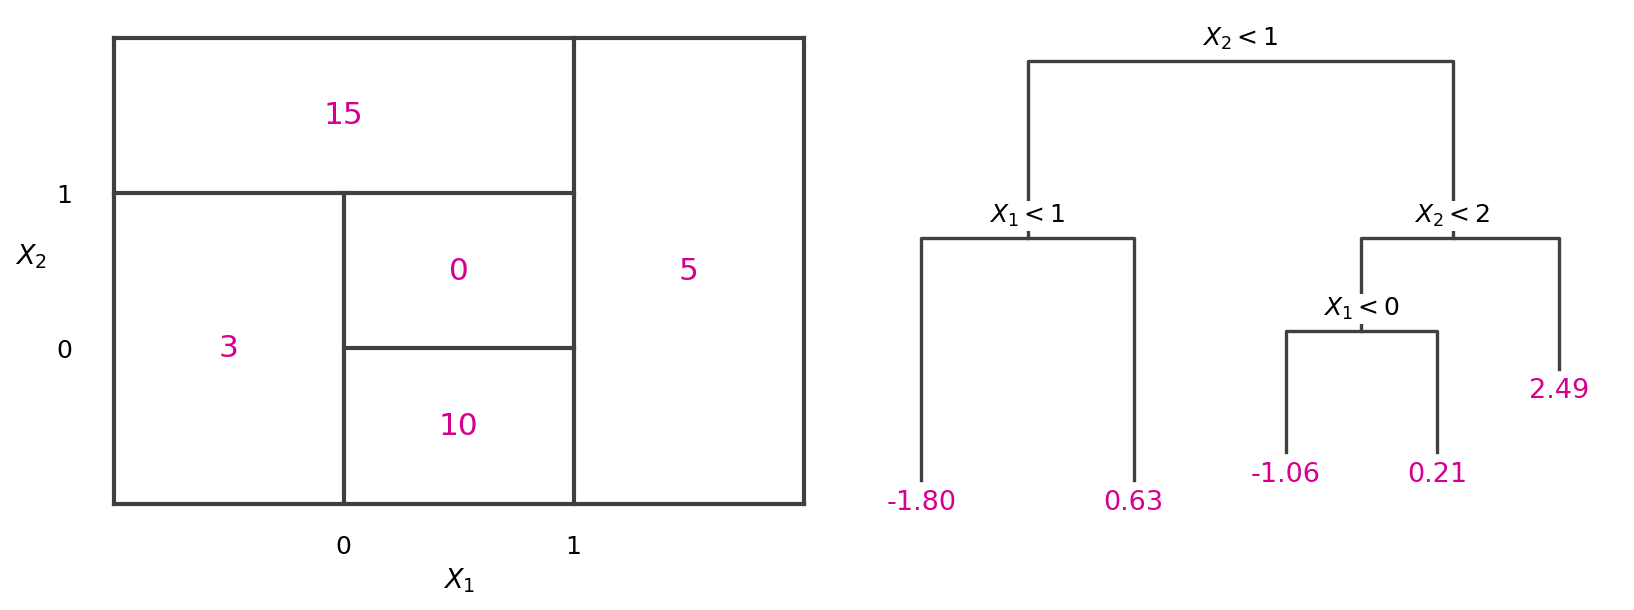

**a.** Sketch the tree that corresponds to the partition in the left panel. Label each internal node with its rule and each leaf with its mean.

*Type your answer here.*

**b.** Write each of the five regions in the left panel as a set, in the form $R = \{X \mid X_1 < a, X_2 \geq b\}$. What does the partition predict for a new observation with $X_1 = 0.5$ and $X_2 = -0.5$?

*Type your answer here.*

**c.** The box with mean 5 is on both sides of the line $X_2 = 1$. Why does that force your tree in part a to make its first split on $X_1$? Could a tree whose first split is $X_2 < 1$ give the same predictions everywhere? If so, how many leaves would it need?

*Type your answer here.*

**d.** Draw the partition that the tree in the right panel describes, in the style of the left panel. Mark each cutpoint on the axes and write the mean in each region.

*Type your answer here.*

**e.** Fill in the blanks below so that `tree_right` follows the tree in the right panel and returns the mean in the leaf where $(X_1, X_2)$ lands. Run the code to draw its predictions over a grid, and check them against your diagram from part d.

In [ ]:
def tree_right(x1, x2):
    if x2 < 1:
        if x1 < 1:
            return -1.80
        return 0.63
    # the right branch of the root splits twice more
    if ____:
        if ____:
            return ____
        return ____
    return ____


x1_grid = np.linspace(-1, 2, 301)
x2_grid = np.linspace(-1, 3, 401)
surface = np.array([[tree_right(a, b) for a in x1_grid] for b in x2_grid])

ramp = LinearSegmentedColormap.from_list("sta363", ["#eec8e1", "#d5008f", "#404040"])
plt.pcolormesh(x1_grid, x2_grid, surface, cmap=ramp, shading="auto")
plt.colorbar(label="predicted Y")
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.show()

*Type your answer here.*

## 2.

Let's take the process that grows a tree, recursive binary splitting, on
six training observations with two predictors.

| observation | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $X_1$ | 1 | 2 | 3 | 4 | 5 | 6 |
| $X_2$ | 5 | 1 | 3 | 6 | 2 | 4 |
| $Y$ | 5 | 5 | 12 | 10 | 0 | 11 |

Before any split, all six observations are predicted with their mean of 7.17,
and the RSS is 106.83.

**a.** Describe, step by step, how recursive binary splitting grows a regression tree. Explain what it searches over at each step, which quantity it uses to choose a split, and what it predicts in each region. What do "top-down" and "greedy" mean here?

*Type your answer here.*

**b.** By hand, find the RSS after the split $X_1 < 2.5$ and after the split $X_2 < 2.5$. Show the mean of each side of each split.

*Type your answer here.*

**c.** Fill in the blanks below to compute the RSS after every candidate split on both predictors. Which predictor and cutpoint does recursive binary splitting choose first? Check your answers to part b against the table, and the choice against the `max_depth=1` tree.

In [ ]:
toy = pd.DataFrame({
    "X1": [1, 2, 3, 4, 5, 6],
    "X2": [5, 1, 3, 6, 2, 4],
    "Y": [5, 5, 12, 10, 0, 11],
})


def split_rss(x, y, s):
    left, right = y[x < s], y[x >= s]
    # each side is predicted with its own mean
    return ____


rows = []
for col in ["X1", "X2"]:
    values = np.sort(toy[col].unique())
    # the cutpoints halfway between adjacent observed values
    cuts = ____
    for s in cuts:
        rows.append({"predictor": col, "cutpoint": s,
                     "RSS after": split_rss(toy[col], toy["Y"], s)})

print(pd.DataFrame(rows).sort_values("RSS after").round(2))

stump = DecisionTreeRegressor(max_depth=1, random_state=363)
stump.fit(toy[["X1", "X2"]], toy["Y"])
print(export_text(stump, feature_names=["X1", "X2"], decimals=2))

*Type your answer here.*

**d.** Fit `DecisionTreeRegressor(max_leaf_nodes=3, random_state=363)` to `toy`, which adds the one split that lowers the RSS the most after the first. Print it with `export_text`. Which region did the second split go to, and what is the training RSS of this three-leaf tree?

*Type your answer here.*

**e.** Take a different three-leaf tree: split first at $X_1 < 2.5$, then split the region $X_1 \geq 2.5$ at $X_2 < 2.5$. By hand, find its leaf means and training RSS. Which three-leaf tree fits the training data better? Use your table from part c to explain why recursive binary splitting missed it.

*Type your answer here.*

## 3.

In the `Carseat` data, `Sales` is unit sales
in thousands, `Price` is the price the company charges at each store,
`Advertising` is the local advertising budget in thousands of dollars, and
`ShelveLoc` is the quality of the shelving location, `Bad`, `Medium` or `Good`.
`pd.get_dummies` turns `ShelveLoc` into the 0/1 columns `ShelveLoc_Good` and
`ShelveLoc_Medium`, with `Bad` as the baseline, and does the same for `Urban`
and `US`. A split on a 0/1 column at 0.5 sends the stores with a 0 to the left.

In [ ]:
Carseats = pd.read_csv(DATA + "Carseats.csv")
X = pd.get_dummies(Carseats.drop(columns=["Sales"]), drop_first=True).astype(float)
y = Carseats["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=363
)

**a.** Fill in the blanks below to fit a tree with `max_depth=3` to the training set and draw it. How many leaves does it have? Which predictor makes the first split, and what does that split tell us about sales?

In [ ]:
tree = DecisionTreeRegressor(max_depth=3, random_state=363).fit(____, ____)

fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(tree, feature_names=list(X.columns), impurity=False, rounded=True,
          precision=2, fontsize=9, ax=ax)
plt.show()

*Type your answer here.*

**b.** Follow the tree for a store with a `Good` shelving location, a `Price` of 120, and an `Advertising` budget of 5. What sales does the tree predict? Write the leaf it lands in as a region, in the form $R = \{X \mid \text{ShelveLoc} = \text{Good}, \dots\}$.

*Type your answer here.*

**c.** Compare the `Price` cutpoints under each shelving location. Does the tree treat the effect of `Price` as the same at every shelving location? Where does `Advertising` enter the tree, and what does that tell us about which stores sell more when they advertise?

*Type your answer here.*

**d.** Use your `split_rss` from Question 2 to run the search for the first split yourself: for each of the 11 columns of `X_train`, find the cutpoint with the smallest RSS. Which column and cutpoint win, and do they match the root of your tree?

*Type your answer here.*

**e.** Compute the test MSE of your tree, of `DummyRegressor()`, and of `LinearRegression()`, each fit on the training set. Which is lowest? Within a leaf the tree predicts the same sales at every price. If sales fall steadily as `Price` rises, how does that help explain the gap to least squares?

*Type your answer here.*

## 4.

A classification tree is grown by the same recursive binary splitting as the
regression tree in Question 2. Each region predicts its most commonly occurring
class, and each split is chosen to lower the Gini index $G$ rather than the
RSS. Here are eight training observations with two predictors and a
qualitative response.

| observation | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| $X_1$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
| $X_2$ | 1 | 3 | 4 | 7 | 6 | 5 | 8 | 2 |
| $Y$ | Yes | No | Yes | Yes | No | No | Yes | No |

Before any split, the node holds 4 Yes and 4 No, so its classification error
rate is $E = 0.5$ and its Gini index is $G = 0.5$. The $E$ or $G$ after a split
is the weighted average of its value in the two regions, with each region
weighted by its share of the eight observations.

**a.** By hand, try two splits: $X_1 < 4.5$ and $X_2 < 6.5$. For each region of each split, give the number of Yes and No, the class it predicts, and its $E$ and $G$. Then find the $E$ and $G$ after each split. Which split does each measure prefer?

*Type your answer here.*

**b.** Fill in the blanks below to compute $E$ and $G$ after every candidate split. How many splits tie for the smallest $E$, and which split does the Gini index choose? Check part a against the table, and the choice against the `max_depth=1` tree, which shows class counts in the order No, Yes.

In [ ]:
toy_class = pd.DataFrame({
    "X1": [1, 2, 3, 4, 5, 6, 7, 8],
    "X2": [1, 3, 4, 7, 6, 5, 8, 2],
    "Y": ["Yes", "No", "Yes", "Yes", "No", "No", "Yes", "No"],
})


def node_purity(y):
    # the proportion of each class in the region
    p = y.value_counts(normalize=True)
    # return E, then G
    return ____, ____


def split_purity(x, y, s):
    left, right = y[x < s], y[x >= s]
    E_left, G_left = node_purity(left)
    E_right, G_right = node_purity(right)
    # weight each region by its share of the observations
    w = len(left) / len(y)
    return ____, ____


rows = []
for col in ["X1", "X2"]:
    values = np.sort(toy_class[col].unique())
    for s in (values[:-1] + values[1:]) / 2:
        E, G = split_purity(toy_class[col], toy_class["Y"], s)
        rows.append({"predictor": col, "cutpoint": s,
                     "E after": E, "G after": G})

print(pd.DataFrame(rows).sort_values("G after").round(3))

class_stump = DecisionTreeClassifier(max_depth=1, random_state=363)
class_stump.fit(toy_class[["X1", "X2"]], toy_class["Y"])
print(export_text(class_stump, feature_names=["X1", "X2"], show_weights=True))

*Type your answer here.*

**c.** Fill in the blanks below to plot $E$, $G$ and the entropy $D$ against $\hat{p}_{m1}$, the proportion of class 1 in region $m$. Which is a straight line on each side of 0.5? ISLP Section 8.1.2 says $E$ is not sufficiently sensitive for tree-growing. Use the plot and part a to explain why.

In [ ]:
# the endpoints 0 and 1 are left off, since log(0) is undefined
p = np.linspace(0.001, 0.999, 999)
E = ____
G = ____
D = ____

plt.plot(p, E, color="#d5008f", label="classification error rate $E$")
plt.plot(p, G, color="#007c86", label="Gini index $G$")
plt.plot(p, D, color="#595959", label="entropy $D$")
plt.xlabel(r"$\hat{p}_{m1}$")
plt.ylabel("value in region $m$")
plt.legend()
plt.show()

*Type your answer here.*

**d.** Use `split_purity` on the region from part b that holds both classes to find the second split, and check it with `max_leaf_nodes=3`. Draw the three-leaf partition as in Question 1, with the predicted class and proportion Yes in each region. What does `predict_proba` return for $X_1 = X_2 = 2$?

*Type your answer here.*

**e.** Code Yes as 1 and No as 0. Show by hand that the RSS in a region with $n_m$ observations and a proportion $\hat{p}_m$ of 1s is $n_m \hat{p}_m(1 - \hat{p}_m) = n_m G / 2$. Which first split would a regression tree on this response pick, and what do its leaf means estimate? Check with `split_rss`.

*Type your answer here.*

*Data from James, G., Witten, D., Hastie, T., Tibshirani, R., and Taylor, J.
(2023). An Introduction to Statistical Learning with Applications in Python.
Springer. Questions 1 to 4 are adapted from Chapter 8 exercises 4, 6, 8 and 3.*